# Permutation pruning for spatial index ensembles

A spatial index ensemble accepts a split when the child's local model improves on its parent's model by at least `split_tolerance`. By default, the `split_tolerance` is applied in sample: the child model is scored on the same rows that it was fit to. For a least-squares submodel, a child model can't fit its own rows worse than the parent model does, so an in-sample improvement almost always occurs. Growth is then controlled mainly by `min_leaf_size` and `max_depth`, not by evidence that the relationship changes over space.

`permutation_prune` tests each accepted split after the ensemble is grown, and removes the splits that a permutation test doesn't support. This notebook shows how the test works on simulated data with a known answer, and then applies it to house prices in King County, Washington.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from geodatasets import get_path
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.ticker import MaxNLocator
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler

from spml.ensemble import KDTreeEnsembleRegressor, QuadtreeEnsembleRegressor
from spml.ensemble.pruning import permutation_prune

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#f0efec"
SLOPE_CMAP = LinearSegmentedColormap.from_list("slope", [BLUE, GRAY, "#e34948"])

/home/lw17329/.cache/pixi-detached-environments/spquadtree-4241042754189784857/envs/default/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## How the test works

For each accepted child, the test statistic is the child's in-sample *gain*: the reduction in summed loss when the child's model replaces the parent's model on the child's rows.

The reference distribution answers this question: how large is the gain when the child is a group of rows with no spatial meaning? To build it, `permutation_prune` permutes the locations of the parent's rows. Each row keeps its features and outcome but moves to another row's location. It then applies the index's split rule to the permuted parent again, refits the children, and records each child's gain. For a quadtree, the split rule is geometric, so a permuted child is a random set of rows of the same size. For a KD-tree, the split plane depends on the parent's residuals and locations, so the plane is chosen again for each permutation. The p-value is the share of permuted gains that are at least as large as the observed gain.

The pruning starts at the deepest children and works up to the root:

1. A child whose own accepted children were all pruned is tested. If its p-value is more than `alpha`, the child is pruned and its parent's model covers the child's area.
2. A child with a surviving descendant is kept without a test. This lets a weak split stay in the tree when it leads to a strong split below it.

## Simulated data with a known answer

In the simulation, the slope on the first feature is $+1$ everywhere in the bottom half of the square. In the top half, the slope is $+1$ on the left and $-1$ on the right. So a local model is needed only in the top half, and the true partition has three regions.

In [2]:
rng = np.random.default_rng(0)
n = 3000
coords = rng.uniform(0, 1, size=(n, 2))
X = rng.normal(size=(n, 2))
true_slope = np.where((coords[:, 1] > 0.5) & (coords[:, 0] > 0.5), -1.0, 1.0)
y = true_slope * X[:, 0] + 0.5 * X[:, 1] + rng.normal(scale=0.5, size=n)

To give the pruning something to remove, grow a KD-tree with `split_tolerance=0`, so that every split above the size floor is accepted.

In [3]:
kdtree = KDTreeEnsembleRegressor(
    model=LinearRegression(), split_tolerance=0, min_leaf_size=30, pbar=False
).fit(X, y, coords)
kdtree_pruned = permutation_prune(kdtree, n_permutations=199, random_state=0)

print(f"Leaves before pruning: {kdtree.n_leaves}")
print(f"Leaves after pruning:  {kdtree_pruned.n_leaves}")

Leaves before pruning: 69
Leaves after pruning:  23


The maps show the leaves before and after pruning. Each leaf is shaded by the slope that its local model estimates for the first feature. The dashed lines mark the true regime boundaries. The KD-tree places each split plane at the residual-weighted median of the cell's coordinates, so a plane can be near a regime boundary without being on it. Pruning removes splits but doesn't move them.

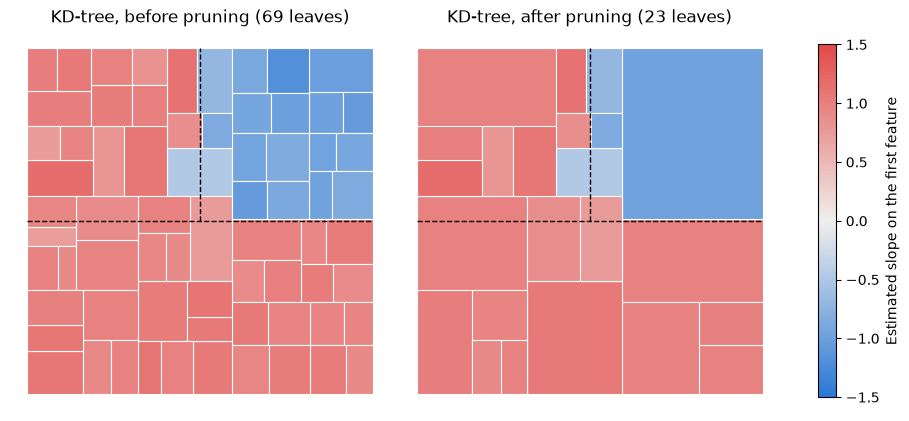

In [4]:
def leaf_slopes(ensemble):
    # The leaf cells, each with the slope of its model on the first feature.
    leaves = ensemble.geoms_.query("not pruned").copy()
    leaves["slope"] = [ensemble.leaves_[i].model_.coef_[0] for i in leaves["index"]]
    # Deep leaves draw last, so they cover the parents that hold the rest of the area.
    return leaves.sort_values("depth")


def plot_slopes(ensembles, titles):
    norm = TwoSlopeNorm(vmin=-1.5, vcenter=0, vmax=1.5)
    f, axes = plt.subplots(1, len(ensembles), figsize=(4.5 * len(ensembles), 4.5),
                           constrained_layout=True)
    for ax, ensemble, title in zip(axes, ensembles, titles):
        leaf_slopes(ensemble).plot(
            "slope", cmap=SLOPE_CMAP, norm=norm, edgecolor="white", linewidth=0.8, ax=ax
        )
        ax.plot([0, 1], [0.5, 0.5], color="black", linestyle="--", linewidth=1)
        ax.plot([0.5, 0.5], [0.5, 1], color="black", linestyle="--", linewidth=1)
        ax.set_title(f"{title} ({ensemble.n_leaves} leaves)")
        ax.set_aspect("equal")
        ax.set_axis_off()
    f.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=SLOPE_CMAP), ax=axes,
               shrink=0.8, label="Estimated slope on the first feature")
    return f


plot_slopes([kdtree, kdtree_pruned], ["KD-tree, before pruning", "KD-tree, after pruning"]);

The `pruning_` attribute of the pruned copy has one row for each accepted child of the original ensemble. The table below lists the children that survive the pruning.

In [5]:
table = kdtree_pruned.pruning_
print(f"Accepted children: {len(table)}")
print(f"Tested: {table.tested.sum()}, pruned: {table.pruned.sum()}")
table.query("not pruned").sort_values("depth").round(4)

Accepted children: 136
Tested: 115, pruned: 101


,parent,child,depth,size,gain,p_value,tested,pruned
135,0,2,1,1204,263.0911,NaN,False,False
134,0,1,1,1796,194.1923,NaN,False,False
130,1,11,2,1010,16.9779,NaN,False,False
131,1,12,2,786,22.8662,NaN,False,False
132,2,21,2,630,573.9250,NaN,False,False
133,2,22,2,574,628.3652,0.005,True,False
126,21,211,3,328,0.7130,NaN,False,False
125,12,122,3,259,110.9219,NaN,False,False
123,11,112,3,480,0.0667,NaN,False,False
124,12,121,3,527,50.4569,NaN,False,False


To see reference distributions, compare two tested children with the gains from 199 permutations of their parents: one child that survives and one that is pruned. `_null_gains` is the internal function that `permutation_prune` uses. It returns one row for each permutation and one column for each child position.

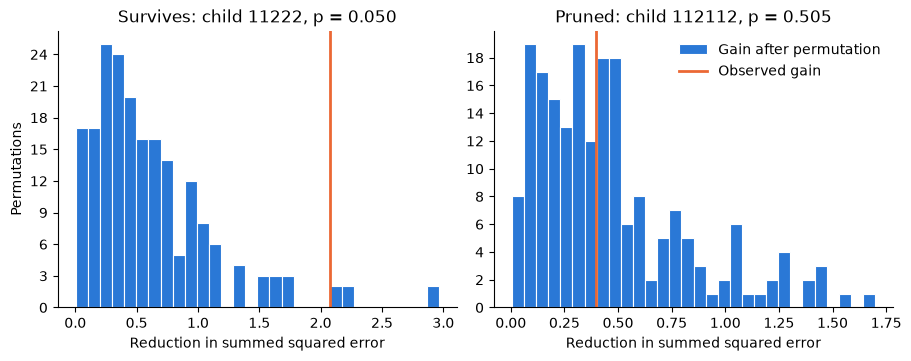

In [6]:
from spml.ensemble.pruning import _gain, _null_gains

cells_by_index = {c.index: c for level in kdtree.levels_.values() for c in level}
tested = table.query("tested")
examples = [
    ("Survives", tested.query("not pruned").sort_values("p_value").iloc[-1]),
    ("Pruned", tested.query("pruned").sort_values("p_value").iloc[len(tested.query("pruned")) // 2]),
]

f, axes = plt.subplots(1, 2, figsize=(9, 3.5), constrained_layout=True)
for ax, (label, row) in zip(axes, examples):
    parent, child = cells_by_index[row.parent], cells_by_index[row.child]
    null = _null_gains(kdtree, parent, 199, np.random.default_rng(1))
    permuted = null[:, child.index - parent.index * 10 - 1]
    permuted = permuted[np.isfinite(permuted)]
    ax.hist(permuted, bins=30, color=BLUE, edgecolor="white", linewidth=0.8,
            label="Gain after permutation")
    ax.axvline(_gain(parent, child), color=ORANGE, linewidth=2, label="Observed gain")
    ax.set_title(f"{label}: child {row.child}, p = {row.p_value:.3f}")
    ax.set_xlabel("Reduction in summed squared error")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Permutations")
axes[1].legend(frameon=False);

For the surviving child, few permuted gains are as large as the observed gain. For the pruned child, the observed gain is a typical value of the reference distribution.

### Quadtree

The same function prunes a quadtree. A quadtree splits each cell at its midpoint, so it can't put a boundary at an arbitrary location, but pruning still removes the quadrants that don't need their own model.

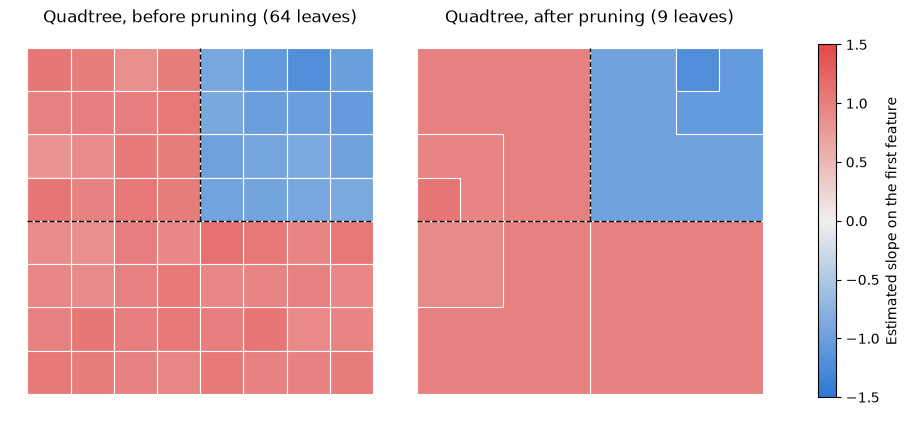

In [7]:
quadtree = QuadtreeEnsembleRegressor(
    model=LinearRegression(), split_tolerance=0, min_leaf_size=30, pbar=False
).fit(X, y, coords)
quadtree_pruned = permutation_prune(quadtree, n_permutations=199, random_state=0)

plot_slopes([quadtree, quadtree_pruned], ["Quadtree, before pruning", "Quadtree, after pruning"]);

### No spatial variation

If the relationship is the same everywhere, each test rejects with probability `alpha`. With `alpha=0.05` and more than 100 tests, about 5 children survive by chance. Each of these children also keeps its ancestors, and each ancestor becomes a leaf over the area of its pruned children. So a few chance rejections can keep many more leaves than the number of rejections.

In [8]:
y_constant = X[:, 0] + 0.5 * X[:, 1] + rng.normal(scale=0.5, size=n)
constant = KDTreeEnsembleRegressor(
    model=LinearRegression(), split_tolerance=0, min_leaf_size=30, pbar=False
).fit(X, y_constant, coords)
constant_pruned = permutation_prune(constant, n_permutations=199, random_state=0)

constant_table = constant_pruned.pruning_.query("tested")
print(f"Leaves before pruning: {constant.n_leaves}")
print(f"Leaves after pruning:  {constant_pruned.n_leaves}")
print(f"Tests: {len(constant_table)}, rejections: {(~constant_table.pruned).sum()}")

Leaves before pruning: 64
Leaves after pruning:  20
Tests: 108, rejections: 6


## House prices in King County

This example fits a KD-tree ensemble with a least-squares submodel to the log sale price of houses in King County, Washington. It uses four structural features, a 20% test set, `min_leaf_size=100`, and `split_tolerance=1e-5`.

In [9]:
features = ["bedrooms", "bathrooms", "sqft_liv", "sqft_lot"]
homes = (
    gpd.read_file(get_path("geoda.home_sales"))
    .drop_duplicates(subset=["long", "lat"])
    .reset_index(drop=True)
    .to_crs(32610)
)
split_rng = np.random.default_rng(85711)
is_test = np.zeros(len(homes), dtype=bool)
is_test[split_rng.choice(len(homes), int(0.2 * len(homes)), replace=False)] = True
train, test = homes[~is_test], homes[is_test]

scaler = StandardScaler().fit(train[features])
X_train, X_test = scaler.transform(train[features]), scaler.transform(test[features])
y_train = np.log(train["price"].to_numpy(float))
y_test = np.log(test["price"].to_numpy(float))
C_train = train.get_coordinates().to_numpy()
C_test = test.get_coordinates().to_numpy()

settings = dict(model=LinearRegression(), split_tolerance=1e-5, min_leaf_size=100, pbar=False)

The comparison has three versions of the same KD-tree:

- **In sample**: the default, with the `split_tolerance` applied in sample.
- **Held out**: `validation_fraction=0.2`, so each child holds back 20% of its rows and must improve on its parent out of sample. The held-out rows are random, so the result depends on `random_state`.
- **Pruned**: the in-sample tree after `permutation_prune`. The permutations are random, so the result depends on `random_state`.

Each random version runs with three seeds.

In [10]:
def summarize(name, seed, ensemble):
    return dict(
        method=name, seed=seed, leaves=ensemble.n_leaves,
        r2_train=r2_score(y_train, ensemble.predict(X_train, C_train)),
        r2_test=r2_score(y_test, ensemble.predict(X_test, C_test)),
    )


in_sample = KDTreeEnsembleRegressor(**settings).fit(X_train, y_train, C_train)
rows = [summarize("In sample", None, in_sample)]
for seed in [0, 1, 2]:
    held_out = KDTreeEnsembleRegressor(
        **settings, validation_fraction=0.2, random_state=seed
    ).fit(X_train, y_train, C_train)
    rows.append(summarize("Held out", seed, held_out))
for seed in [0, 1, 2]:
    pruned = permutation_prune(in_sample, n_permutations=99, random_state=seed)
    rows.append(summarize("Pruned", seed, pruned))

results = pd.DataFrame(rows)
results.round(3)

,method,seed,leaves,r2_train,r2_test
0,In sample,NaN,110,0.852,0.827
1,Held out,0.0,42,0.803,0.797
2,Held out,1.0,52,0.815,0.807
3,Held out,2.0,30,0.796,0.788
4,Pruned,0.0,86,0.849,0.828
5,Pruned,1.0,86,0.849,0.827
6,Pruned,2.0,84,0.849,0.828


Applying the `split_tolerance` out of sample depends strongly on the seed. Each split is accepted or rejected as the tree grows, so one unlucky set of held-out rows near the root stops a large part of the tree from growing. Pruning tests the splits after the tree is grown, uses all of the training rows, and gives similar trees for different seeds.

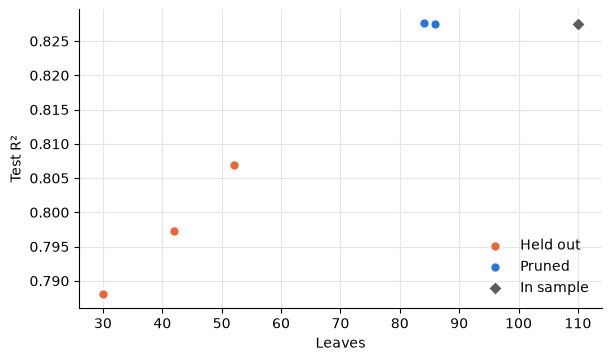

In [11]:
f, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
for name, color in [("Held out", ORANGE), ("Pruned", BLUE)]:
    subset = results.query("method == @name")
    ax.scatter(subset.leaves, subset.r2_test, s=64, color=color, edgecolor="white",
               linewidth=2, label=name, zorder=3)
base = results.query("method == 'In sample'").iloc[0]
ax.scatter(base.leaves, base.r2_test, s=64, color="#5c5c58", marker="D",
           edgecolor="white", linewidth=2, label="In sample", zorder=3)
ax.set_xlabel("Leaves")
ax.set_ylabel("Test R²")
ax.legend(frameon=False, loc="lower right")
ax.grid(color="#e6e5e1", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False);

## Limits of the test

- **Exchangeability.** The test assumes that the parent's rows are exchangeable when the relationship doesn't vary inside the parent. If the residuals are spatially autocorrelated, nearby rows share errors, contiguous children differ more than random sets of rows do, and the p-values are too small. Omitted variables in a hedonic price model usually cause this, so some surviving splits in the King County tree can reflect residual autocorrelation rather than a change in the relationship.
- **Multiple tests.** The pruning runs one test for each tested child. At `alpha=0.05`, about 1 test in 20 rejects by chance. `permutation_prune` doesn't adjust `alpha` for the number of tests.
- **Selection.** For a KD-tree, the reference distribution includes the choice of the split plane, because the plane is chosen again for each permutation. The tree structure above the tested split is fixed.